In [1]:
import numpy as np
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression

# Generate synthetic classification data
X, y = make_classification(
    n_samples=1000,  # Number of samples
    n_features=2,  # Number of features
    n_informative=2,  # Number of informative features
    n_redundant=0,  # Number of redundant features
    n_clusters_per_class=1,  # Number of clusters per class
    class_sep=20,  # Class separation factor
    random_state=42,
    hypercube=False,  # Random state for reproducibility
)

In [2]:
class MyLogisticRegression:

    def __init__(self, X: np.ndarray, y: np.ndarray, neta=0.5, epochs=10000):
        self.neta = neta
        self.epochs = epochs
        self.X = np.insert(X, 0, 1, axis=1)
        self.y = y
        self.weights = np.ones(self.X.shape[1])

    def Sigmoid(self, Z):
        return 1 / (1 + np.exp(-Z))

    def Optimise(self):
        for _ in tqdm(range(self.epochs), desc="Optimising Weights"):
            y_hat = self.Sigmoid(np.dot(self.X, self.weights))
            m = self.y.shape[0]
            self.weights = self.weights + self.neta * (
                np.dot((self.y - y_hat), self.X) / m
            )
        return self.weights[1:], self.weights[0]

Optimising Weights: 100%|██████████| 10000/10000 [00:00<00:00, 33455.80it/s]


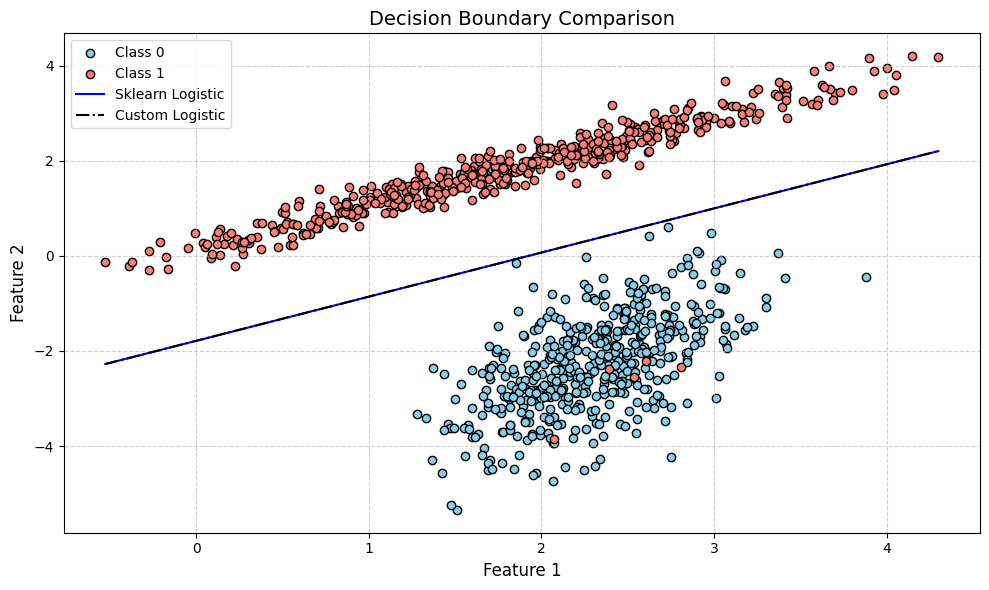

In [3]:
# Train sklearn logistic regression
sk_model = LogisticRegression(penalty=None, solver="sag")
sk_model.fit(X, y)


# Train custom model
my_model = MyLogisticRegression(X, y)
my_coef, my_intercept = my_model.Optimise()

# Get sklearn model parameters
sk_intercept = sk_model.intercept_[0]
sk_coef = sk_model.coef_[0]

# Plotting
plt.figure(figsize=(10, 6))
plt.scatter(
    X[y == 0][:, 0], X[y == 0][:, 1], color="skyblue", label="Class 0", edgecolor="k"
)
plt.scatter(
    X[y == 1][:, 0], X[y == 1][:, 1], color="salmon", label="Class 1", edgecolor="k"
)


# Decision boundary function
def plot_decision_boundary(coef, intercept, label, color, linestyle):
    x_vals = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
    y_vals = -(coef[0] * x_vals + intercept) / coef[1]
    plt.plot(x_vals, y_vals, label=label, color=color, linestyle=linestyle)


# Plot both decision boundaries
plot_decision_boundary(sk_coef, sk_intercept, "Sklearn Logistic", "blue", "solid")
plot_decision_boundary(my_coef, my_intercept, "Custom Logistic", "black", "-.")

plt.title("Decision Boundary Comparison", fontsize=14)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("CustomLogistic.png")
plt.show()